# Exercise 3: Regularisation and Generalisation

This experiment investigates whether dropout and data augmentation improve the generalisation of the CNN from Exercise2. Each technique is tested separately against the unchanged CNN baseline. 

## 1. Experimental approach

The CNN has two convolutional layers with 32 and 64 filters, followed by a fully connected output layer. The baseline has no dropout or random augmentation. For the dropout experiment, dropout with probability 0.5 is placed between the flattened features and the output layer. For the augmentation experiment, random cropping with four pixels of padding and horizontal flipping are applied only to training images. Padded random cropping introduces small translations while preserving the 32 x 32 image size.

Both models are trained from fresh initial weights. The same seed, image split, normalisation, batch size, optimiser, learning rate and epoch budget are retained. No combined dropout-and-augmentation model is used, so each comparison isolates one intervention.

In [4]:
import json
import random
import time
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

PROJECT_ROOT = Path.cwd().parent
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_3"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT_ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

SEED = 42
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
baseline_results = json.loads(
    (PROJECT_ROOT / "artifacts" / "exercise_2" / "results.json").read_text(encoding="utf-8")
)
print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS, "| Learning rate:", LEARNING_RATE)

Device: cpu
Batch size: 64 | Epochs: 20 | Learning rate: 0.001


## 2. Training and validation partitions

The split is reproduced using the exact seeded permutation in Exercise 2: the first 45,000 indices are used for training and the remaining 5,000 for validation. This is the existing random split, rather than a newly generated stratified split. Separate dataset objects prevent training augmentation from changing validation images. A dedicated data-loader generator gives the same shuffled training order for each experiment.

Validation and clean training evaluation use only tensor conversion and normalisation. The official test set is loaded after both training runs have finished.

In [2]:
clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
augmentation_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
clean_source = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=clean_transform)
augmented_source = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=False, transform=augmentation_transform)
split_indices = torch.randperm(50_000, generator=torch.Generator().manual_seed(42)).tolist()
train_indices, val_indices = split_indices[:45_000], split_indices[45_000:]
np.savez(ARTIFACT_DIR / "split_indices.npz", train=train_indices, validation=val_indices)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=DEVICE.type == "cuda")
train_eval_loader = DataLoader(Subset(clean_source, train_indices), shuffle=False, **loader_args)
val_loader = DataLoader(Subset(clean_source, val_indices), shuffle=False, **loader_args)

def make_train_loader(augmentation=False):
    source = augmented_source if augmentation else clean_source
    return DataLoader(Subset(source, train_indices), shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), **loader_args)

print("Training:", len(train_indices), "| Validation:", len(val_indices))

Training: 45000 | Validation: 5000


## 3. CNN and dropout placement

The learned layers are identical to Exercise 2: Conv(3,32), Conv(32,64), and Linear(4096,10). Both convolutions use 3 x 3 kernels with padding 1, ReLU and 2 x 2 max pooling. Dropout has no trainable parameters, so all conditions have 60,362 learned parameters. Dropout is switched off automatically during evaluation.

In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self, dropout_probability=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(dropout_probability)
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        return self.fc(self.dropout(self.flatten(x)))

set_seed(SEED)
initial_weights = {name: value.detach().clone() for name, value in CIFAR10CNN().state_dict().items()}
parameter_count = sum(value.numel() for value in initial_weights.values())
print("Trainable parameters:", f"{parameter_count:,}")

Trainable parameters: 60,362


## 4. Training procedure

Cross-entropy and Adam with learning rate 0.001 are used for 20 epochs, without weight decay, a scheduler or early stopping. Loss is averaged by the number of images rather than by the number of batches. Each model receives the same fresh initial weights and a new optimiser. Validation is recorded after each epoch without updating weights.

The final-epoch comparison is defined before the new test results are obtained. It does not compare a validation-selected model against a final-epoch baseline.

In [4]:
criterion = nn.CrossEntropyLoss()

def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, count = 0.0, 0, 0
    with torch.enable_grad() if training else torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            count += labels.size(0)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
    return {"loss": loss_sum / count, "accuracy": correct / count}

def train_condition(name, dropout_probability, augmentation):
    set_seed(SEED)
    model = CIFAR10CNN(dropout_probability).to(DEVICE)
    model.load_state_dict(initial_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_train_loader(augmentation)
    history = []
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train = epoch_metrics(model, train_loader, optimizer)
        validation = epoch_metrics(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train["loss"],
                        "train_accuracy": train["accuracy"], "val_loss": validation["loss"],
                        "val_accuracy": validation["accuracy"]})
        pd.DataFrame(history).to_csv(ARTIFACT_DIR / f"{name}_history.csv", index=False)
        print(f"{name} | Epoch {epoch:02d}/{EPOCHS} | "
              f"train loss {train['loss']:.4f}, accuracy {train['accuracy']:.4f} | "
              f"val loss {validation['loss']:.4f}, accuracy {validation['accuracy']:.4f}", flush=True)
    checkpoint = ARTIFACT_DIR / f"{name}_final_epoch.pth"
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, checkpoint)
    summary = {"history": history, "training_seconds": time.perf_counter() - started,
               "checkpoint": str(checkpoint.relative_to(PROJECT_ROOT)),
               "dropout_probability": dropout_probability, "augmentation": augmentation,
               "train": epoch_metrics(model, train_eval_loader),
               "validation": epoch_metrics(model, val_loader)}
    (ARTIFACT_DIR / f"{name}_development.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return summary

dropout_results = train_condition("dropout", dropout_probability=0.5, augmentation=False)
augmentation_results = train_condition("augmentation", dropout_probability=0.0, augmentation=True)

dropout | Epoch 01/20 | train loss 1.4157, accuracy 0.4978 | val loss 1.1287, accuracy 0.6058
dropout | Epoch 02/20 | train loss 1.1095, accuracy 0.6110 | val loss 1.0141, accuracy 0.6594
dropout | Epoch 03/20 | train loss 0.9942, accuracy 0.6529 | val loss 0.9209, accuracy 0.6826
dropout | Epoch 04/20 | train loss 0.9250, accuracy 0.6779 | val loss 0.9108, accuracy 0.6896
dropout | Epoch 05/20 | train loss 0.8836, accuracy 0.6939 | val loss 0.8558, accuracy 0.7082
dropout | Epoch 06/20 | train loss 0.8375, accuracy 0.7096 | val loss 0.8141, accuracy 0.7202
dropout | Epoch 07/20 | train loss 0.8109, accuracy 0.7174 | val loss 0.8070, accuracy 0.7254
dropout | Epoch 08/20 | train loss 0.7892, accuracy 0.7254 | val loss 0.7909, accuracy 0.7272
dropout | Epoch 09/20 | train loss 0.7708, accuracy 0.7334 | val loss 0.7679, accuracy 0.7286
dropout | Epoch 10/20 | train loss 0.7486, accuracy 0.7400 | val loss 0.7654, accuracy 0.7362
dropout | Epoch 11/20 | train loss 0.7370, accuracy 0.7441 |

## 5. Learning curves

Training curves show online metrics while parameters are changing, with dropout or augmentation active where applicable. Validation curves use a fixed end-of-epoch model with dropout off and deterministic images. Therefore the training curves should not be interpreted as clean train-to-test gaps.

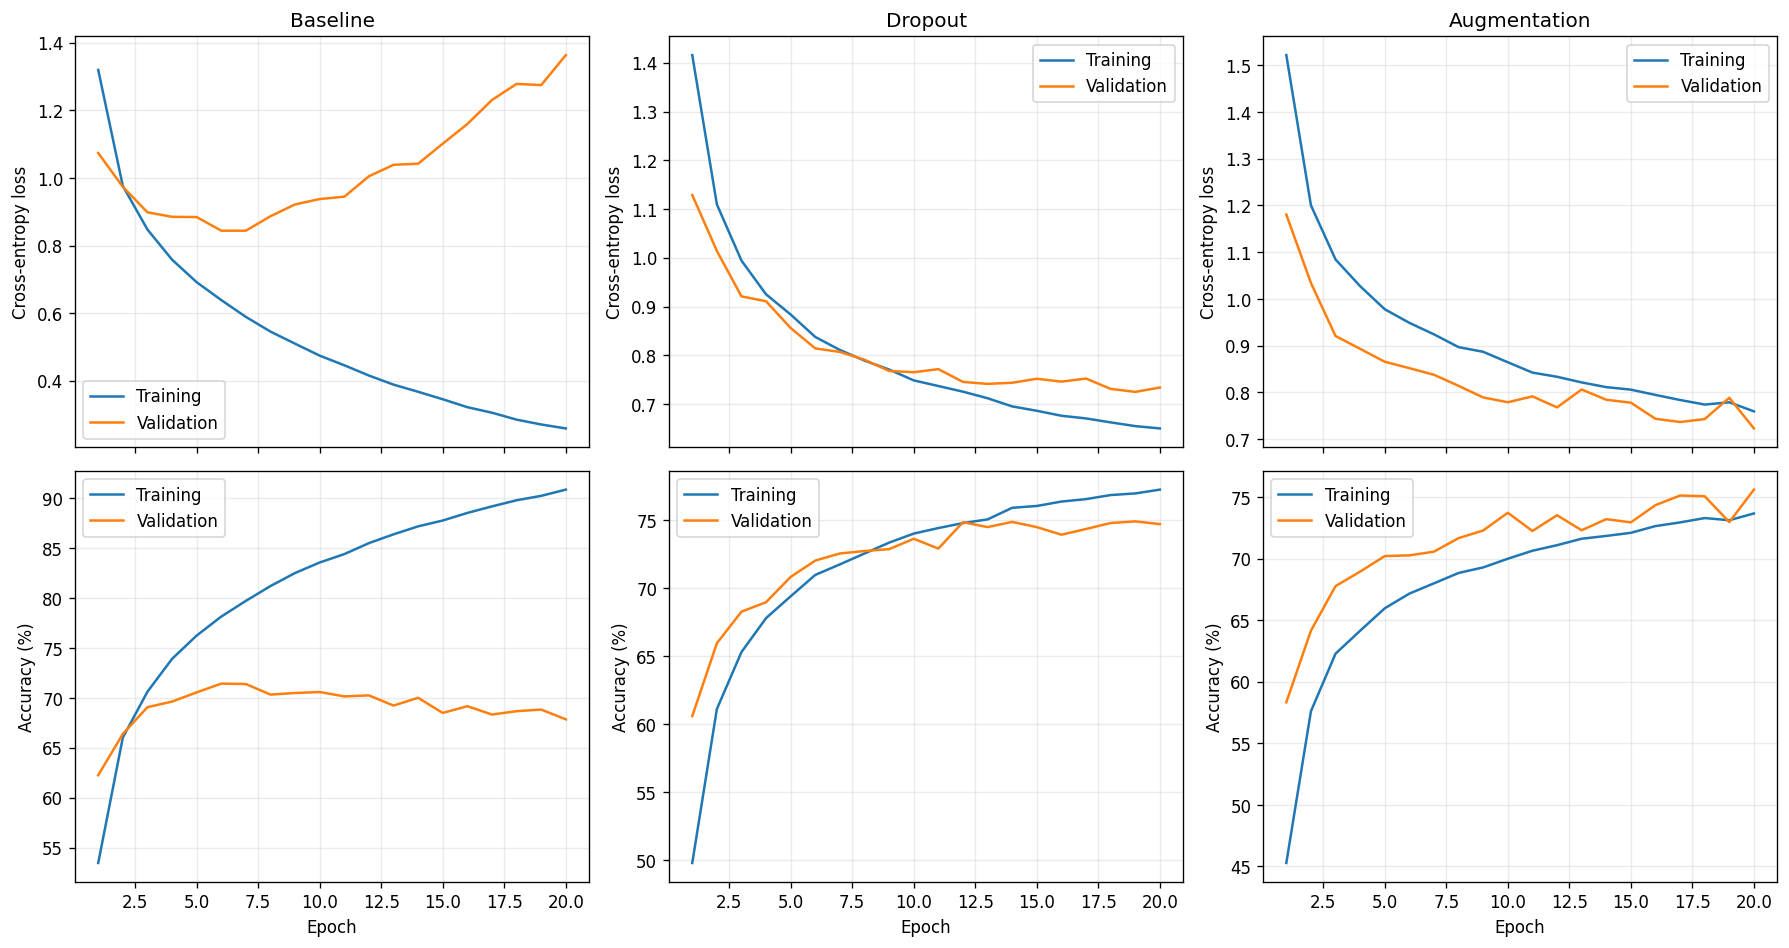

In [5]:
baseline_history = pd.DataFrame(baseline_results["history"])
baseline_history["epoch"] = np.arange(1, len(baseline_history) + 1)
histories = {"Baseline": baseline_history,
             "Dropout": pd.DataFrame(dropout_results["history"]),
             "Augmentation": pd.DataFrame(augmentation_results["history"])}
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for column, (name, frame) in enumerate(histories.items()):
    axes[0, column].plot(frame["epoch"], frame["train_loss"], label="Training")
    axes[0, column].plot(frame["epoch"], frame["val_loss"], label="Validation")
    axes[0, column].set(title=name, ylabel="Cross-entropy loss")
    axes[1, column].plot(frame["epoch"], 100 * frame["train_accuracy"], label="Training")
    axes[1, column].plot(frame["epoch"], 100 * frame["val_accuracy"], label="Validation")
    axes[1, column].set(xlabel="Epoch", ylabel="Accuracy (%)")
    for row in range(2):
        axes[row, column].legend()
        axes[row, column].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160)
plt.show()

## 6. Final training and test comparison

The baseline measurements are reused from `artifacts/exercise_2/results.json`; the baseline is not retrained or changed. New test evaluation takes place after both regularised models have completed training. All final training accuracies use clean images with dropout off, so they can be compared with test accuracy under the same evaluation conditions.

The gap is training accuracy minus test accuracy, expressed in percentage points. A smaller gap is only useful when considered together with test accuracy: a model that performs poorly on both splits can also have a small gap.

,Condition,Parameters,Train accuracy (%),Validation accuracy (%),Test accuracy (%),Train-test gap (pp),Train loss,Test loss
0,Baseline,60362,92.089,67.86,68.50,23.589,0.227,1.383
1,Dropout,60362,85.122,74.70,75.24,9.882,0.454,0.731
2,Augmentation,60362,78.104,75.62,76.00,2.104,0.632,0.702


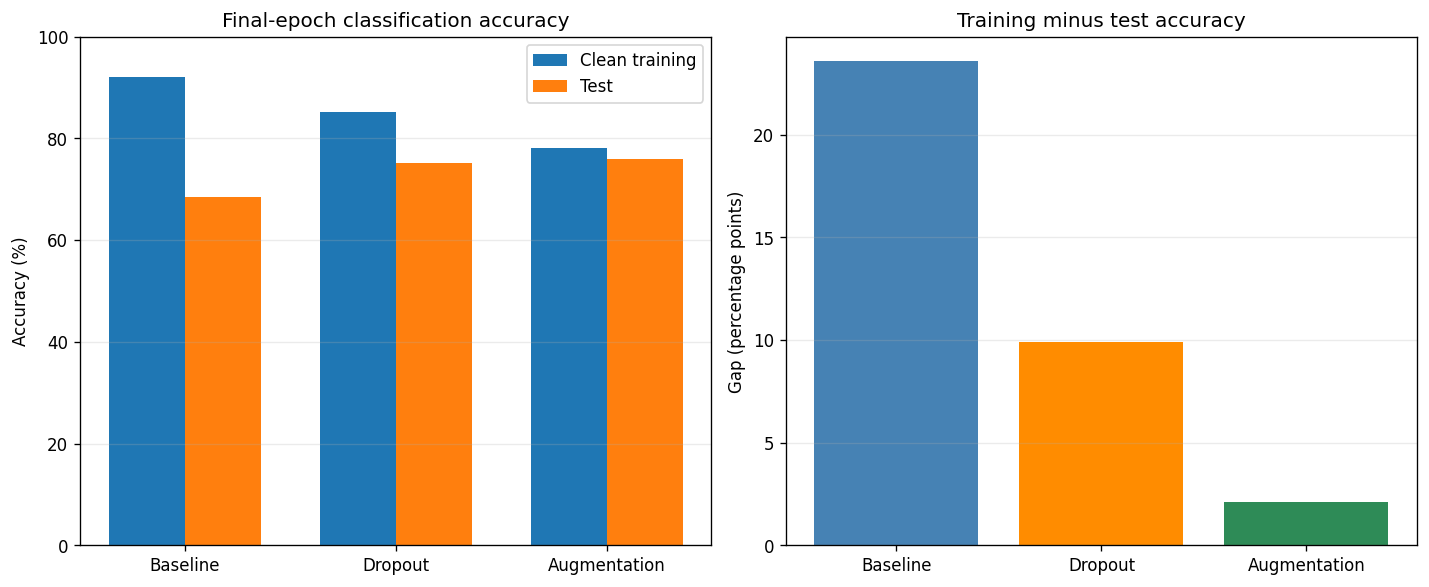

In [6]:
test_dataset = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=clean_transform)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
for name, result in [("dropout", dropout_results), ("augmentation", augmentation_results)]:
    model = CIFAR10CNN(result["dropout_probability"]).to(DEVICE)
    model.load_state_dict(torch.load(PROJECT_ROOT / result["checkpoint"], map_location=DEVICE, weights_only=True))
    result["test"] = epoch_metrics(model, test_loader)
    del model

baseline_metrics = baseline_results["final_epoch"]["metrics"]
conditions = {"Baseline": baseline_metrics, "Dropout": dropout_results, "Augmentation": augmentation_results}
rows = []
for name, result in conditions.items():
    rows.append({"Condition": name, "Parameters": parameter_count,
                 "Train accuracy (%)": 100 * result["train"]["accuracy"],
                 "Validation accuracy (%)": 100 * result["validation"]["accuracy"],
                 "Test accuracy (%)": 100 * result["test"]["accuracy"],
                 "Train-test gap (pp)": 100 * (result["train"]["accuracy"] - result["test"]["accuracy"]),
                 "Train loss": result["train"]["loss"], "Test loss": result["test"]["loss"]})
comparison = pd.DataFrame(rows)
display(comparison.round(3))
comparison.to_csv(ARTIFACT_DIR / "regularisation_comparison.csv", index=False)
results = {"seed": SEED, "split_seed": 42, "split_method": "torch.randperm(50000), seed 42; first 45000 training",
           "device": str(DEVICE), "torch_version": torch.__version__, "cpu_threads": torch.get_num_threads(),
           "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
           "optimizer": "Adam", "weight_decay": 0, "selection": "final epoch for all primary comparisons",
           "normalisation": {"mean": CIFAR_MEAN, "std": CIFAR_STD},
           "baseline_source": "artifacts/exercise_2/results.json", "baseline": baseline_metrics,
           "dropout": dropout_results, "augmentation": augmentation_results}
(ARTIFACT_DIR / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")

positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(positions - 0.18, comparison["Train accuracy (%)"], 0.36, label="Clean training")
axes[0].bar(positions + 0.18, comparison["Test accuracy (%)"], 0.36, label="Test")
axes[0].set_xticks(positions, comparison["Condition"])
axes[0].set(title="Final-epoch classification accuracy", ylabel="Accuracy (%)", ylim=(0, 100))
axes[0].legend()
axes[1].bar(comparison["Condition"], comparison["Train-test gap (pp)"], color=["steelblue", "darkorange", "seagreen"])
axes[1].set(title="Training minus test accuracy", ylabel="Gap (percentage points)")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "regularisation_comparison.png", dpi=160)
plt.show()

## 7. Discussion

In [7]:
base = comparison.set_index("Condition").loc["Baseline"]
paragraphs = []
for name in ["Dropout", "Augmentation"]:
    row = comparison.set_index("Condition").loc[name]
    change = row["Test accuracy (%)"] - base["Test accuracy (%)"]
    gap_change = base["Train-test gap (pp)"] - row["Train-test gap (pp)"]
    outcome = "improved" if change > 0 else "reduced" if change < 0 else "did not change"
    gap_description = "smaller" if gap_change >= 0 else "larger"
    paragraphs.append(
        f"**{name}.** Clean training accuracy was {row['Train accuracy (%)']:.2f}% and test accuracy was "
        f"{row['Test accuracy (%)']:.2f}%, giving a gap of {row['Train-test gap (pp)']:.2f} percentage points. "
        f"Compared with the unchanged baseline, this {outcome} test accuracy by {abs(change):.2f} percentage points. "
        f"The gap was {abs(gap_change):.2f} percentage points {gap_description}."
    )
discussion = "\n\n".join(paragraphs)
display(Markdown(discussion))
(ARTIFACT_DIR / "measured_findings.md").write_text("# Exercise 3: measured findings\n\n" + discussion + "\n", encoding="utf-8")

**Dropout.** Clean training accuracy was 85.12% and test accuracy was 75.24%, giving a gap of 9.88 percentage points. Compared with the unchanged baseline, this improved test accuracy by 6.74 percentage points. The gap was 13.71 percentage points smaller.

**Augmentation.** Clean training accuracy was 78.10% and test accuracy was 76.00%, giving a gap of 2.10 percentage points. Compared with the unchanged baseline, this improved test accuracy by 7.50 percentage points. The gap was 21.48 percentage points smaller.

Both techniques improved test accuracy and reduced the train-to-test gap compared with the unchanged baseline. Augmentation gave the highest test accuracy, but its advantage over dropout was only 0.76 percentage points. Dropout therefore provided a slightly smaller improvement rather than showing no benefit. With one run per condition, this small difference is not enough to conclude that augmentation will always perform better.

The baseline loss curves show training loss falling while validation loss rises after the early epochs. The regularised models show a much smaller separation. Augmentation sometimes has validation loss below online training loss because the training images are deliberately harder, while validation images are unchanged. This is why the final comparison uses clean evaluation-mode training accuracy.

Dropout randomly suppresses flattened features during training, making the classifier less dependent on particular activations. This can reduce overfitting, although a probability of 0.5 may also slow learning or remove useful information from a small CNN. A lower training score is therefore not sufficient evidence that dropout is beneficial; the test score and loss must also be considered.

Augmentation exposes the network to different positions and mirrored views of training objects. This encourages the network to learn features that are less sensitive to exact image placement. The crop-and-flip combination is evaluated as one pipeline, so this experiment cannot identify the individual contribution of cropping or flipping. If its benefit is limited, possible explanations include the strength of the transformations, the model's capacity and the fixed 20-epoch budget.

The comparison uses one seed and one split, so small differences may reflect random training variation. The saved Exercise 2 baseline was trained on a different recorded environment; the new results record their actual device and PyTorch version. Hardware and library differences prevent exact repeatability and make runtime comparisons inappropriate. Reusing the baseline preserves its original measurements, but identical initial weights across the old and new runs cannot be confirmed without its saved initial state. Both new conditions share the same initial weights with each other.

The baseline test score was already reported in Exercise 2. The new conditions and settings were fixed before their test evaluation; test scores are descriptive and are not used to change augmentation, dropout or the epoch count.